# NanoLM — three trained Transformers, from a fresh Colab session

A curated AI Engineering submission demo. We built a decoder-only Transformer
from explicit Q/K/V projections, scaled causal attention, residual blocks and
next-token cross-entropy. These three models learned Tiny Shakespeare from scratch.
No pretrained model or research training is run here.

**Selected states:** E02 Compact5000, B01 Balanced3000, F01 Quality1750.
This notebook verifies public downloads, actual model shapes, causality, trained
attention and genuine generation. CPU is sufficient. Choose **Runtime → Run all**
in a fresh CPU runtime with internet. No token, Drive mount or developer PC needed.

Small-corpus language models can repeat dialogue, misspell words and emit invalid
UTF-8 bytes. Better validation BPB does not guarantee coherent writing.

## 1. Inspect the native runtime
Record first; do not replace Colab’s native PyTorch or assume the research pins fit it.

In [1]:
import sys, platform, json, importlib.metadata as metadata, time
from pathlib import Path
STARTED = time.perf_counter()
native = {"python": sys.version, "os": platform.platform()}
for package in ["torch", "numpy", "tokenizers"]:
    try: native[package] = metadata.version(package)
    except metadata.PackageNotFoundError: native[package] = "absent"
print(json.dumps(native, indent=2))

{
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.11.0+cpu",
  "numpy": "2.1.3",
  "tokenizers": "0.23.2"
}


## 2. Clone the exact source
The reviewed scientific base is aa4bb5f. The following pinned submission helper commit adds wrappers/tests only. Its review status is documented in the submission report.

In [2]:
import subprocess, os
SOURCE = "1f402d9e3b902e7d3e78565969476d2d7af06502"
REPOSITORY = "https://github.com/rayyan-merchant/Nano-Language-Model.git"
WORK = Path("/content/NanoLM-submission")
ENV = Path("/content/nanolm-submission-env")
PY = ENV / "bin/python"
command_env = dict(os.environ)
command_env.update({"GIT_TERMINAL_PROMPT": "0", "GIT_CONFIG_GLOBAL": os.devnull,
                    "GIT_CONFIG_NOSYSTEM": "1", "HF_HUB_DISABLE_IMPLICIT_TOKEN": "1", "MPLBACKEND": "Agg"})
def run(argv, cwd=None, tail=2500):
    result = subprocess.run([str(x) for x in argv], cwd=cwd, env=command_env,
                            text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    print(result.stdout[-tail:])
    if result.returncode: raise RuntimeError(f"Command failed (exit {result.returncode}); stop and inspect output")
    return result.stdout
if WORK.exists(): raise FileExistsError("Use a fresh Colab runtime; preserve earlier evidence")
run(["git", "clone", REPOSITORY, WORK])
run(["git", "checkout", SOURCE], cwd=WORK)
print("Exact source:", run(["git", "rev-parse", "HEAD"], cwd=WORK).strip())
assert not run(["git", "status", "--porcelain"], cwd=WORK).strip()

Cloning into '/content/NanoLM-submission'...



Note: switching to '1f402d9e3b902e7d3e78565969476d2d7af06502'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 1f402d9 fix: isolate Colab plotting backend and pin fresh-install pip

1f402d9e3b902e7d3e78565969476d2d7af06502

Exact source: 1f402d9e3b902e7d3e78565969476d2d7af06502



## 3. Provision the compatible CPU interpreter
Isolated Python3.11.14 and torch2.5.1+cpu; NumPy1.26.4 and tokenizers0.21.0. Native Colab remains installed. Installation downloads about a few hundred MB; no GPU is allocated. The package is installed normally, not editable.

In [3]:
run([sys.executable, "-m", "pip", "install", "uv==0.12.7"])
run([sys.executable, "-m", "uv", "venv", "--python", "3.11.14", "--seed", ENV])
run([PY, "-m", "pip", "install", "--upgrade", "pip==26.2.1"])
run([PY, "-m", "pip", "install", "torch==2.5.1", "--index-url", "https://download.pytorch.org/whl/cpu"])
run([PY, "-m", "pip", "install", "-r", "requirements.txt", "-r", "requirements-studio.txt"], cwd=WORK)
run([PY, "-m", "pip", "install", ".", "--no-deps"], cwd=WORK)
run([PY, "-m", "pip", "check"], cwd=WORK)
EVIDENCE = WORK / "outputs/submission-colab"
EVIDENCE.mkdir(parents=True)
(EVIDENCE / "native-environment.json").write_text(json.dumps(native, indent=2))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 20.1/20.1 MB 61.8 MB/s eta 0:00:00



 Downloaded cpython-3.11.14-linux-x86_64-gnu (download)
Using CPython 3.11.14
Creating virtual environment with seed packages at: nanolm-submission-env
 + packaging==26.3
 + pip==26.2.1
 + setuptools==84.0.0
 + wheel==0.48.0
Activate with: source nanolm-submission-env/bin/activate



Looking in indexes: https://download.pytorch.org/whl/cpu
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 174.7/174.7 MB 61.0 MB/s  0:00:02
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.2/6.2 MB 68.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 536.2/536.2 kB 10.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 71.6 MB/s  0:00:00




ng contourpy-1.3.3-cp311-cp311-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl (355 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 116.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 55.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 120.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 806.6/806.6 kB 26.0 MB/s  0:00:00




Processing ./.
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Created wheel for nano-language-model: filename=nano_language_model-0.1.0-py3-none-any.whl size=31159 sha256=d67fa6bb243cf2efa623d9f75ad56cb1dbbda6753e0003dc65daa38dd4ce7283
  Stored in directory: /tmp/pip-ephem-wheel-cache-rnxqdumq/wheels/39/b0/df/dfd32f5cab08781a8f611f60741d2a6a810da946197c3fb791
Successfully built nano-language-model



No broken requirements found.



187

## 4. Import the real implementation
The notebook calls the installed package through its isolated interpreter. It does not copy Transformer code into notebook cells.

In [4]:
def section(name):
    run([PY, "-m", "tools.submission_demo", "--artifacts", WORK / "model_artifacts",
         "--section", name, "--output", EVIDENCE / name], cwd=WORK, tail=1500)
    return json.loads((EVIDENCE / name / "receipt.json").read_text())
environment = section("environment")
print(json.dumps(environment["environment"], indent=2))

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/environment/receipt.json", "models": 0, "generation_cases": 0, "reference_cases": 0, "exact_reference_matches": 0, "measured_seconds": 0.34265488599999117}

{
  "python": "3.11.14 (main, Feb 12 2026, 00:42:50) [Clang 21.1.4 ]",
  "executable": "/content/nanolm-submission-env/bin/python",
  "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "torch": "2.5.1+cpu",
  "cuda_available": false,
  "source_commit": "1f402d9e3b902e7d3e78565969476d2d7af06502",
  "git_dirty": false,
  "freeze": [
    "annotated-doc==0.0.5",
    "annotated-types==0.8.0",
    "anyio==4.15.1",
    "certifi==2026.7.22",
    "charset-normalizer==3.5.2",
    "click==8.5.0",
    "contourpy==1.3.3",
 

## 5. Numerical, causal and tiny-overfit checks
The existing trusted fixture uses a tiny synthetic sequence and60 optimizer updates. It is a bounded debugging test, not Shakespeare research training. Attention/scaling, split/merge, positions, shifted targets, future-token exclusion and finite gradients are also tested.

In [5]:
test_log = run([PY, "-m", "pytest", "tests/test_core.py", "tests/test_submission.py", "-v"], cwd=WORK, tail=7000)
(EVIDENCE / "core-tests.txt").write_text(test_log)

============================= test session starts ==============================
platform linux -- Python 3.11.14, pytest-8.3.4, pluggy-1.7.0 -- /content/nanolm-submission-env/bin/python
cachedir: .pytest_cache
rootdir: /content/NanoLM-submission
configfile: pyproject.toml
plugins: anyio-4.15.1
collecting ... collected 23 items

tests/test_core.py::test_tokenizer_roundtrip PASSED                      [  4%]
tests/test_core.py::test_split_and_shift PASSED                          [  8%]
tests/test_core.py::test_attention_numerical_and_mask PASSED             [ 13%]
tests/test_core.py::test_head_split_merge PASSED                         [ 17%]
tests/test_core.py::test_position_formulas PASSED                        [ 21%]
tests/test_core.py::test_model_causal_loss_and_gradients[sinusoidal] PASSED [ 26%]
tests/test_core.py::test_model_causal_loss_and_gradients[learned] PASSED [ 30%]
tests/test_core.py::test_model_causal_loss_and_gradients[rope] PASSED    [ 34%]
tests/test_core.py::test_i

2903

## 6. Retrieve all three public packages
Anonymous HTTPS, immutable HF revision, exact file-size/SHA256 and selected-identity checks. This stops on failure; no cached or random weights are substituted. Original research checkpoint hashes remain separate from derived safetensors hashes.

In [6]:
run([PY, "-m", "tools.submission_models", "--output", WORK / "model_artifacts"], cwd=WORK, tail=5000)
download = json.loads((WORK / "model_artifacts/download_receipt.json").read_text())
print("Verified files:", len(download["files"]), "at", download["revision"])

{
  "repository": "rayyanmerchant/nanolm-studio-weights",
  "revision": "719a7f3a4955225a9818e872b08c1503de601a81",
  "authentication": "none; anonymous HTTPS, no Hub cache",
  "files": [
    {
      "path": "e02/metadata.json",
      "bytes": 9085,
      "sha256": "98c0506578ec682c01a78d2e9709ae3b0af1c86a5e70fa6924bed25a15455410"
    },
    {
      "path": "e02/model.safetensors",
      "bytes": 8698368,
      "sha256": "5258e0db6839a2ee95b24083fc4bda43299c73d79310de5e8291d6bc3e4f7150"
    },
    {
      "path": "b01/metadata.json",
      "bytes": 8987,
      "sha256": "9f91554e2f96f4b04c3c67cee498d77e10af7531459ecd178601984084cd422d"
    },
    {
      "path": "b01/model.safetensors",
      "bytes": 12260216,
      "sha256": "0ea6ff2972740d2775f5d2da331d41395e2f75b36076436ec0b2a43ebcf18e3f"
    },
    {
      "path": "f01/metadata.json",
      "bytes": 9066,
      "sha256": "151e633288551e1b032c16f5998f3aab301ffbd5ef22877aa6288f286d10cb0c"
    },
    {
      "path": "f01/model.safete

## 7. Inspect the actually loaded architectures
Parameter counts come from loaded PyTorch objects. Historical BPB is previously measured validation evidence, not likelihood measured in this notebook.

In [7]:
from IPython.display import display, Markdown, Image
models = section("models")
rows = ["|Model|Selected update|Actual parameters|Blocks|Width|Position|Historical validation BPB|", "|---|---:|---:|---:|---:|---|---:|"]
for m in models["models"]:
    c = m["architecture"]
    rows.append(f"|{m['id'].upper()}|{m['selected_step']}|{m['parameters']:,}|{c['n_layers']}|{c['d_model']}|{c['position']}|{m['historical_validation_bpb']:.8f}|")
display(Markdown("\n".join(rows)))

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/models/receipt.json", "models": 3, "generation_cases": 0, "reference_cases": 0, "exact_reference_matches": 0, "measured_seconds": 0.8894432170000073}



|Model|Selected update|Actual parameters|Blocks|Width|Position|Historical validation BPB|
|---|---:|---:|---:|---:|---|---:|
|E02|5000|2,173,056|4|192|sinusoidal|2.02659521|
|B01|3000|3,062,784|6|192|rope|1.98493095|
|F01|1750|6,046,560|8|240|rope|1.98376817|

## 8. Real Byte-BPE tokenization
The canonical train-only1,024-entry tokenizer is hash verified. Generation crops its history to the final128 tokens and resets local positions consistently with training. Byte-level decoding can replace invalid generated UTF-8 with U+FFFD; it does not repair language.

In [8]:
print(json.dumps(models["tokenizer"], indent=2, ensure_ascii=False))
assert models["tokenizer"]["vocabulary"] == 1024
assert models["tokenizer"]["decoded"] == models["tokenizer"]["prompt"]

{
  "sha256": "2d7b1e84c8055eb5b9483a3fe6e4e3c9e348f5a28506ba19a0dc1644f0b36d55",
  "vocabulary": 1024,
  "prompt": "To be, or not to be",
  "ids": [
    396,
    304,
    11,
    529,
    321,
    287,
    304
  ],
  "decoded": "To be, or not to be",
  "context": 128,
  "long_prompt_cropped_to_last_tokens": 128
}


## 9. Trained attention and future-token invariance
B01 step3000, layer0/head0. The heatmap uses `return_attention=True` on the actual selected weights. Rows are queries, columns keys. A changed future suffix must not change earlier logits; probabilities above the diagonal must be exactly zero. This is a trained-attention demonstration, not the later complete assignment figure audit.

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/attention/receipt.json", "models": 3, "generation_cases": 0, "reference_cases": 0, "exact_reference_matches": 0, "measured_seconds": 1.7798458859999755}

{
  "model": "b01",
  "checkpoint_step": 3000,
  "prompt": "ROMEO:\nTo be, or not to be",
  "input_ids": [
    813,
    25,
    198,
    396,
    304,
    11,
    529,
    321,
    287,
    304
  ],
  "input_shape": [
    1,
    10
  ],
  "attention_shapes": [
    [
      1,
      6,
      10,
      10
    ],
    [
      1,
      6,
      10,
      10
    ],
    [
      1,
      6,
      10,
      10
    ],
    [
      1,
      6,
      10,
      10
    ],
    [
      1,
      6,
      10,
      10
    ],
    [

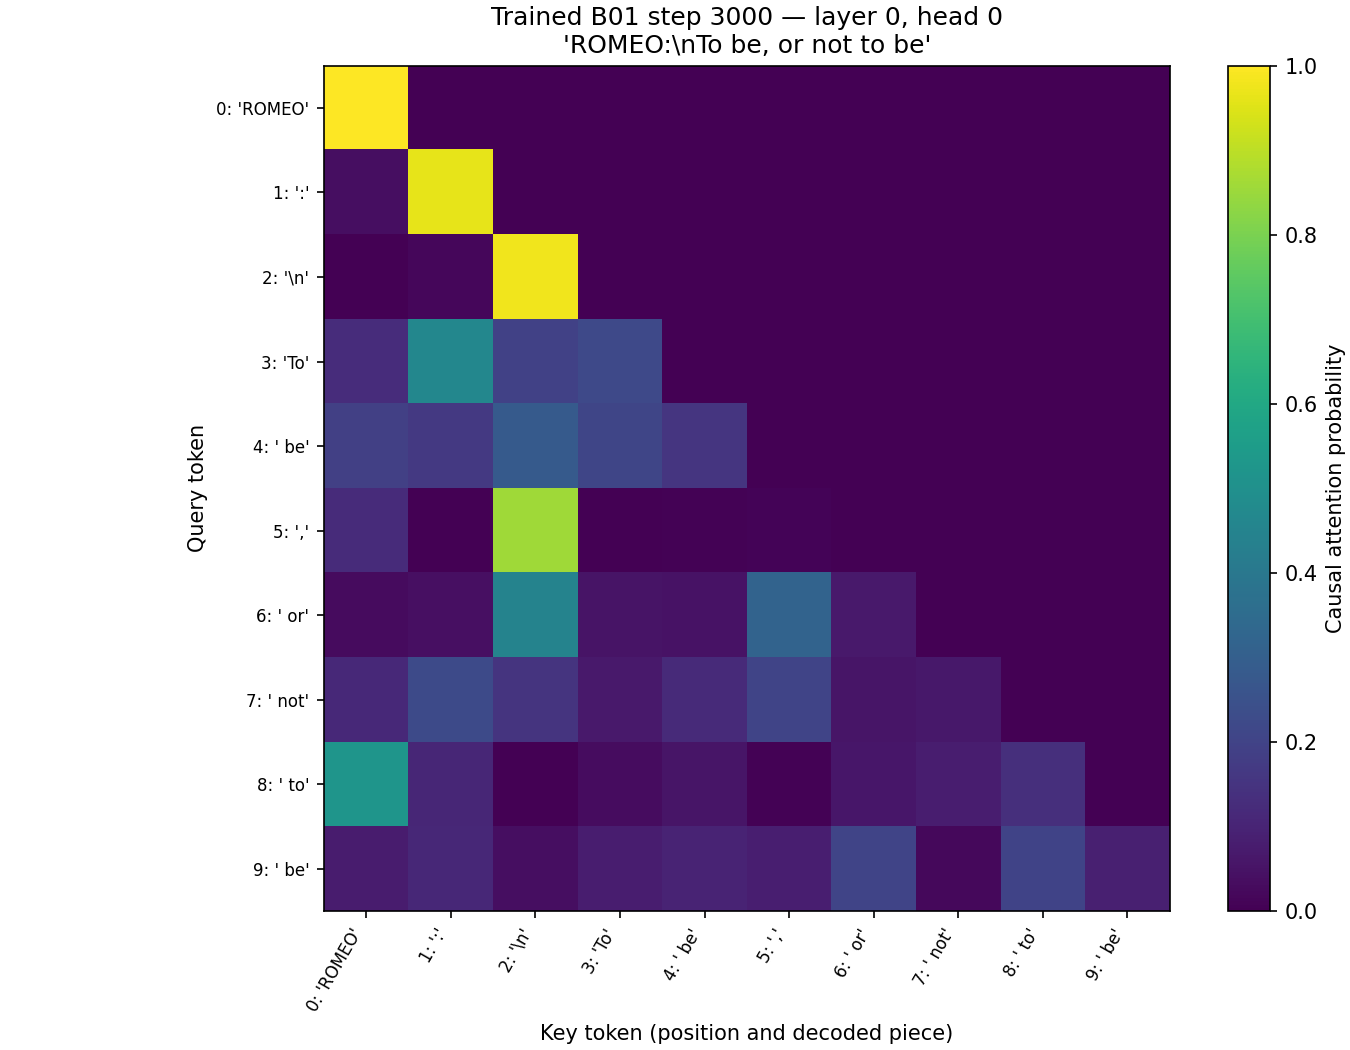

In [9]:
audited = section("attention")
a = audited["attention"]
print(json.dumps({k: v for k, v in a.items() if k != "probabilities"}, indent=2))
display(Image(filename=str(EVIDENCE / "attention/trained_attention.png")))

## 10. Genuine generation — all three models
Five fixed prompts × greedy/sampling × three models =30 cases,32 new tokens each, temperature0.7, seed42. Complete raw token IDs and unedited decoded outputs are saved in the receipt. Below are the three required prompts in sampling mode; all30 remain available. Exact cross-platform token equality is measured where prior reference cases exist, not assumed.

In [10]:
generated = section("generation")
for row in generated["generations"]:
    if row["prompt"] in ["To be, or not to be", "ROMEO:\n", "JULIET:\n"] and not row["greedy"]:
        print("=" * 65)
        print(row["model"].upper(), "step", row["checkpoint_step"], "sampling T=0.7 seed42 new_tokens32", f"{row['seconds']:.3f}s")
        print(row["full_output"])
reference = [r for r in generated["generations"] if r["reference_exact_ids"] is not None]
print("Exact raw-ID reference matches:", sum(r["reference_exact_ids"] for r in reference), "/", len(reference))
print("Full output/token receipt:", EVIDENCE / "generation/receipt.json")

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/generation/receipt.json", "models": 3, "generation_cases": 30, "reference_cases": 12, "exact_reference_matches": 12, "measured_seconds": 11.303080692000094}

E02 step 5000 sampling T=0.7 seed42 new_tokens32 0.163s
To be, or not to bed,
The trembles of the brick of the world
And lean, by the nor any soldier.


E02 step 5000 sampling T=0.7 seed42 new_tokens32 0.153s
ROMEO:
I cannot tell thee.

DUCHESS OF YORK:
Dear, by this, and I have forgive some speed
E02 step 5000 sampling T=0.7 seed42 new_tokens32 0.162s
JULIET:
I cannot tell thee.

DUCHESS OF YORK:
Then have the third of the north,
Staying
B01 step 3000 sampling T=0.7 seed42 new_tokens32 0.337s
To be, or not

## 11. Compare inference cost and historical validation
These are actual32-token CPU generation measurements in this session, not training runtimes or robust hardware benchmarks. One seed provides no variance estimate. BPB differences do not establish coherence.

In [11]:
import statistics
rows = ["|Model|Historical validation BPB|Median measured32-token generation (s)|", "|---|---:|---:|"]
for m in generated["models"]:
    times = [r["seconds"] for r in generated["generations"] if r["model"] == m["id"]]
    rows.append(f"|{m['id'].upper()}|{m['historical_validation_bpb']:.8f}|{statistics.median(times):.3f}|")
display(Markdown("\n".join(rows)))

|Model|Historical validation BPB|Median measured32-token generation (s)|
|---|---:|---:|
|E02|2.02659521|0.161|
|B01|1.98493095|0.316|
|F01|1.98376817|0.505|

## 12. Real API, without public tunneling
An in-process FastAPI client calls canonical B01 generation and compares its decoded output with the shared generator. The deployed website is not required.

In [12]:
api = section("api")
print(json.dumps(api["api"], indent=2, ensure_ascii=False))

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/api/receipt.json", "models": 3, "generation_cases": 0, "reference_cases": 0, "exact_reference_matches": 0, "measured_seconds": 1.5135110090000126}

{
  "status": 200,
  "readiness": 200,
  "canonical_decoding_equal": true,
  "response": {
    "model_id": "b01",
    "model_name": "NanoLM Balanced",
    "checkpoint_step": 3000,
    "prompt": "ROMEO:\n",
    "continuation": "I'll tell thee, I'll not be a king,\nAnd nothing but a man.\n\nJULIET:\nI know not, sir, if",
    "full_output": "ROMEO:\nI'll tell thee, I'll not be a king,\nAnd nothing but a man.\n\nJULIET:\nI know not, sir, if",
    "generated_tokens": 32,
    "output_characters": 87,
    "prompt_tokens": 3

## 13. Clean-process reload and final provenance
Every section launches a separate Python process and reloads verified packages. This final independent invocation confirms continued loading after earlier processes exit.

In [13]:
run([PY, "-m", "tools.submission_demo", "--artifacts", WORK / "model_artifacts",
     "--section", "models", "--output", EVIDENCE / "restart"], cwd=WORK)
assert not run(["git", "status", "--porcelain"], cwd=WORK).strip()
summary = {"source_commit": environment["environment"]["source_commit"],
           "package_revision": download["revision"], "verified_models": [m["id"] for m in models["models"]],
           "generation_cases": len(generated["generations"]), "raw_ID_reference_cases": len(reference),
           "exact_raw_ID_matches": sum(r["reference_exact_ids"] for r in reference),
           "trained_attention_future_error": a["future_logit_max_abs_error"], "api_status": api["api"]["status"],
           "total_measured_notebook_seconds": time.perf_counter() - STARTED,
           "research_optimizer_updates": 0, "tiny_fixture_updates_per_test": 60}
(EVIDENCE / "summary.json").write_text(json.dumps(summary, indent=2))
print(json.dumps(summary, indent=2))

/content/nanolm-submission-env/lib/python3.11/site-packages/fastapi/testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa
{"receipt": "/content/NanoLM-submission/outputs/submission-colab/restart/receipt.json", "models": 3, "generation_cases": 0, "reference_cases": 0, "exact_reference_matches": 0, "measured_seconds": 0.8887414670000453}


{
  "source_commit": "1f402d9e3b902e7d3e78565969476d2d7af06502",
  "package_revision": "719a7f3a4955225a9818e872b08c1503de601a81",
  "verified_models": [
    "e02",
    "b01",
    "f01"
  ],
  "generation_cases": 30,
  "raw_ID_reference_cases": 12,
  "exact_raw_ID_matches": 12,
  "trained_attention_future_error": 0.0,
  "api_status": 200,
  "total_measured_notebook_seconds": 120.689191908,
  "research_optimizer_updates": 0,
  "tiny_fixture_updates_per_test": 60
}


## 14. What this demonstrates — and its limits

We used the original implementation, verified the three exact selected packages,
inspected real trained attention, checked causality, generated authentic text and
called the genuine API. All receipts are in `outputs/submission-colab` for download
before the runtime expires. The model packages can be retrieved again by hash.

These models learned a small Shakespeare corpus with single-seed experiments.
F01/B01 prolonged training deteriorated on validation; selection uses the preserved
best states. Dialogue loops, malformed words and invalid-byte decoding remain real
limitations. Neither lower BPB nor a selected pleasing sample proves coherent
language. Outputs above are unedited. No test-set assessment, fine-tuning or new
research training occurred. The manual-attention/MLM-versus-CLM evidence audit,
final academic report and presentation are the **next separately reviewed phase**.